In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colorbar import ColorbarBase
from matplotlib.colors import Normalize
import os
# import re

In [2]:
from analysis import small_label_settings
plt.style.use('default')
plt.rcParams.update(small_label_settings)

In [3]:
none_barcode = "NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE"

fish_filter = ['fish1',    'fish10',    'fish12',    'fish13',    'fish14',    'fish15',
    'fish16',    'fish17',    'fish18',     'fish2',    'fish22',    'fish26',
    'fish35',    'fish37',    'fish38',     'fish4',    'fish40',    'fish42',
    'fish44',    'fish45',     'fish5',    'fish50',    'fish51',     'fish8']

sample_filter = 1

In [4]:
df = pd.read_csv(os.path.join('..', 'experiments', 'keep_questionable', 'final_data.csv')) 

if sample_filter is not None:
    if isinstance(sample_filter, int):
        sample_filter = [sample_filter]
    df = df[df["sample"].isin(sample_filter)]

# if fish_filter is not None:
#     if isinstance(fish_filter, str):
#         fish_filter = [fish_filter]
#     df = df[df["fish"].isin(fish_filter)]

# Remove NONE barcode and fishwater samples
df = df[df["barcode"] != none_barcode]
df = df[~df['fish'].str.contains('ctrl', case=False, na=False)]
df = df[~df["fish"].str.contains("fishwater", case=False)]

print("Samples included:", df["sample"].unique())
print("Fish included:", df["fish"].unique())

Samples included: [1]
Fish included: <StringArray>
[ 'fish1', 'fish10', 'fish11', 'fish13', 'fish14', 'fish15', 'fish17',
 'fish18',  'fish2', 'fish21', 'fish23', 'fish26', 'fish35', 'fish37',
 'fish38', 'fish40', 'fish41', 'fish42', 'fish43', 'fish45',  'fish5',
  'fish6',  'fish8',  'fish9']
Length: 24, dtype: str


In [5]:
# fish_barcode_counts is a DataFrame where each row is a fish, each column is a barcode,
# and the entry is the number of reads of that barcode
fish_barcode_counts = (
    df
    .groupby(["fish", "barcode"])["reads"]
    .sum()
    .unstack(fill_value=0)
)

# Reorder fish numerically
fish_barcode_counts = fish_barcode_counts.reindex(
    sorted(fish_barcode_counts.index, key=lambda x: int(x.replace("fish", "")))
)

fish_list = fish_barcode_counts.index.tolist()
n_fish = len(fish_list)

In [6]:
fish_barcode_counts['40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NONE_NONE_NONE']

fish
fish1        0
fish2        0
fish5        0
fish6        0
fish8        0
fish9        0
fish10       0
fish11       0
fish13       0
fish14       0
fish15       0
fish17       0
fish18       0
fish21    9200
fish23       0
fish26       0
fish35       0
fish37       0
fish38       0
fish40       0
fish41       0
fish42       0
fish43       0
fish45    5487
Name: 40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NONE_NONE_NONE, dtype: int64

In [7]:
#7. CALCULATE COSINE SIMILARITY
cos_sim_matrix = cosine_similarity(fish_barcode_counts)
cos_sim_df = pd.DataFrame(cos_sim_matrix, index=fish_list, columns=fish_list)

In [8]:
barcode_fish_appearances = (
    df.groupby("barcode")["fish"]
      .nunique()
      .rename("n_unique_fish")
)

def get_fish_barcodes(fish):
    """
    This function inputs a fish and returns a dataframe with the following columns:
    - barcode
    - reads
    - unique (boolean, True if the barcode does not appear in any other fish)
    """
    fish_barcodes = df[df['fish'] == fish].groupby('barcode', as_index = False).agg({'reads': 'sum'})
    fish_barcodes = fish_barcodes.join(
        barcode_fish_appearances.eq(1).rename("unique"),
        on="barcode"
    ).sort_values('reads', ascending = False)

    return fish_barcodes

In [9]:
# Compute shared barcode counts
shared_counts = np.dot(
    (fish_barcode_counts > 0).astype(int),
    (fish_barcode_counts > 0).astype(int).T
)
shared_df = pd.DataFrame(shared_counts, index=fish_list, columns=fish_list)

In [10]:
custom_cmap = LinearSegmentedColormap.from_list(
    "geyser",
    [
        (0.00, "#0B3A35"),
        (0.01, "#37736AFF"),
        (0.02, "#4B9B92FF"),
        (0.05, "#75A895FF"),
        (0.1, "#7BB594FF"),
        (0.25, "#A3D1A3FF"),
        (0.4, "#D6E29BFF"),
        (0.55, "#EAEA9DFF"),
        (0.7, "#E6DA75FF"),
        (0.85, "#ECC957FF"),
        (0.9, "#E8AB51FF"),
        (0.95, "#DE9C31FF"),
        (1.0, "#D77229FF")
    ],
    N=256
)

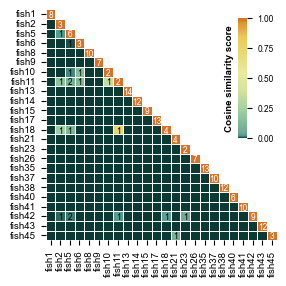

In [11]:
# Fish-to-fish cosine similarity
mask = np.triu(np.ones_like(cos_sim_df, dtype=bool), k=1)  # hide upper triangle

n_fish = len(fish_list)
fig_size = 3
annot_font_size = 6
label_font_size = 6

fig, ax = plt.subplots(figsize=(fig_size, fig_size))
ax = sns.heatmap(
    cos_sim_df,
    mask=mask,
    cmap=custom_cmap,
    fmt='d',
    annot_kws={"size": annot_font_size, "ha": "center", "va": "center"},
    cbar=False,
    square=True,
    linewidths=0.5,
    xticklabels=True,
    yticklabels=True
)

# Annotate shared barcodes
for i in range(len(shared_df)):
    for j in range(len(shared_df)):
        if mask[i, j]:   # skip masked upper triangle
            continue

        if i == j:
            fish_barcodes = get_fish_barcodes(shared_df.index[i])
            value = len(fish_barcodes[fish_barcodes['unique']])
        else:
            value = shared_df.iloc[i, j]
            
        if value != 0:
            ax.text(
                j + 0.5, i + 0.58,          # center of the square
                str(value),
                ha='center', va='center',
                fontsize=annot_font_size,
                color='white' if i == j else 'black',
            )

ax.tick_params(axis='both', labelsize=label_font_size)
plt.setp(ax.get_xticklabels(), fontsize=label_font_size, rotation=0)
plt.setp(ax.get_yticklabels(), fontsize=label_font_size, rotation=0)

ax.set_xticks([i + 0.5 for i in range(len(fish_list))])
ax.set_yticks([i + 0.5 for i in range(len(fish_list))])
ax.set_xticklabels(fish_list, fontsize=label_font_size, rotation=90, font = 'Arial')
ax.set_yticklabels(fish_list, fontsize=label_font_size, rotation=0, font = 'Arial')

ax.set_xlabel('')
ax.set_ylabel('')
# ax.set_title('Barcode overlap\nbetween fish', y = 0.92, fontweight = 'bold')

cax = fig.add_axes([0.77, 0.45, 0.03, 0.4]) # Paper settings
norm = Normalize(vmin=0, vmax=1)
cbar = ColorbarBase(
    cax, 
    cmap=custom_cmap,
    norm=norm,
    orientation='vertical'
)
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6)
cbar.set_label("Cosine similarity score", fontweight = 'bold', fontsize=7, labelpad=3)
cbar.ax.yaxis.set_label_position("left")
cbar.ax.yaxis.tick_right()
tick_positions = [0, 0.25, 0.5, 0.75, 1]
tick_labels = [f'{tick:.2f}' for tick in tick_positions]
cbar.set_ticks(tick_positions)
cbar.set_ticklabels(tick_labels)

plt.savefig(os.path.join('images', 'cosines', 'sample1_cosine.png'), dpi = 300)
plt.savefig(os.path.join('images', 'cosines', 'sample1_cosine.svg'))